# Linear Regression from Scratch — Recitation (Lecture 8)

**Main example: Prostate Cancer data**, following the organization of the original *The Elements of Statistical Learning* Python notebook.

**Credit / source:** This teaching adaptation is based on the [**Prostate Cancer** notebook by GitHub user **empathy87**](https://github.com/empathy87/The-Elements-of-Statistical-Learning-Python-Notebooks/blob/master/examples/Prostate%20Cancer.ipynb), from [*The Elements of Statistical Learning — Python Notebooks*](https://github.com/empathy87/The-Elements-of-Statistical-Learning-Python-Notebooks). The example follows the prostate-data discussion in *The Elements of Statistical Learning* by Trevor Hastie, Robert Tibshirani, and Jerome Friedman. The underlying prostate data derive from Stamey et al. (1989). Original source is credited here for the dataset choice, analysis structure, CV methodology, and teaching inspiration. The implementation below has been rewritten and modernized for this recitation.

**Topics:** OLS closed form → Ridge and Lasso → K-fold cross-validation → bias–variance tradeoff.

**Run:** Place `Prostate_Cancer.csv` in the same directory as this notebook, then run cells from top to bottom. If dependencies are missing: `pip install numpy pandas matplotlib seaborn scikit-learn statsmodels`.

**What changed from the original notebook?** We retain the prostate dataset, original training/test split, OLS, Ridge/Lasso, and CV plots; omit PCA, PLS, and best-subset selection (outside today's scope). We add a small NumPy OLS/MLE demonstration, a forward-stagewise comparison to the Lasso path, a synthetic bias–variance demonstration, and visualizations/animations throughout. Modernized the scikit-learn CV calls and fitted scalers *inside each training fold* to prevent leakage.

## 1. The prostate cancer dataset

**The problem.** Prostate-specific antigen (PSA) is a protein measured by a blood test; a high PSA level can be a sign of prostate cancer. Stamey et al. (1989) studied **97 men who were about to have their prostate removed** (radical prostatectomy); after surgery, the removed prostate was examined, which gave 8 measurements of the tumor and the gland. The target `lpsa` is a continuous number, so this is a **regression** problem, and the whole recitation is about fitting one equation:

$$\hat y=\beta_0+\sum_{j=1}^{8}\beta_jx_j,\qquad\text{i.e.}\qquad\widehat{\text{lpsa}}=\beta_0+\beta_1\,\text{lcavol}+\beta_2\,\text{lweight}+\beta_3\,\text{age}+\beta_4\,\text{lbph}+\beta_5\,\text{svi}+\beta_6\,\text{lcp}+\beta_7\,\text{gleason}+\beta_8\,\text{pgg45}.$$

The rest of the notebook (Sections 3–7) only asks three questions about this one equation:

| Question | Where it's answered |
|---|---|
| How do we compute $\beta_0,\dots,\beta_8$ from the 67 training patients? | Sec. 3: OLS, the normal equation |
| That computation gives unstable $\beta_j$ when features overlap — how do we fix it? | Sec. 4: Ridge, Lasso |
| The fix adds a new knob $\alpha$ — how much, and why does it matter? | Sec. 5–6: cross-validation, bias–variance |
| Did any of this actually help? | Sec. 7: the test set, used once |

**The features $x_1,\dots,x_8$**, always in this order ($\beta_j$ is the coefficient of feature $j$, $\beta_0$ the intercept):

| $j$ | Column | Meaning | Type | Values in the data |
|---:|---|---|---|---|
| 1 | `lcavol` | log of the cancer (tumor) volume in cc | continuous | −1.35 to 3.82 (0.26 to 46 cc) |
| 2 | `lweight` | log of the prostate weight in g | continuous | 2.37 to 4.78 (11 to 119 g) |
| 3 | `age` | age in years | continuous | 41 to 79 |
| 4 | `lbph` | log of the amount of benign prostatic hyperplasia (non-cancerous enlargement of the prostate) | continuous | −1.39 to 2.33; 43 patients at the floor −1.386 |
| 5 | `svi` | seminal vesicle invasion: has the cancer spread into the seminal vesicles? | binary | 1 = yes (21 patients), 0 = no (76) |
| 6 | `lcp` | log of the capsular penetration: how far the cancer has grown through the capsule around the prostate | continuous | −1.39 to 2.90; 45 patients at the floor −1.386 |
| 7 | `gleason` | Gleason score: a pathologist's grade of how abnormal the cancer cells look; higher = more aggressive | ordinal | 6 (35 patients), 7 (56), 8 (1), 9 (5) |
| 8 | `pgg45` | percentage of the tumor graded as Gleason pattern 4 or 5 (the aggressive patterns) | percentage | 0 to 100; exactly 0 for 35 patients |

**Why logs?** Volumes, weights, and PSA are positive and strongly right-skewed: a few patients have very large values. The log makes them roughly symmetric (see the first figure below) and turns multiplicative effects into additive ones, which suits a linear model. The value −1.386 = log(0.25) is the smallest recorded value of `lbph` and `lcp`; almost half of the patients sit exactly there, most likely meaning "none detected".

**Train/test split.** The column `train` (T/F) is the split used in *The Elements of Statistical Learning*: **67 training and 30 test patients**. We keep it instead of drawing a new random split, so our numbers can be compared with the book. Everything learned or chosen (scaling, $\beta$, $\alpha$) uses the 67 training patients only; the 30 test patients are used once, in Section 7.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, lars_path  # LinearRegression: Sec. 6 polynomial demo only
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import statsmodels.api as sm

sns.set_theme(style="whitegrid", context="notebook")
np.set_printoptions(precision=3, suppress=True)
RANDOM_STATE = 69438       # retain the original notebook's CV seed

# Animations are embedded as a JavaScript player (play / pause / slider),
# so they run in Jupyter and VS Code and stay in the saved notebook.
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

plt.rcParams["animation.embed_limit"] = 60   # MB per animation


def show_animation(fig, update, frames, interval=150):
    anim = FuncAnimation(fig, update, frames=frames, interval=interval)
    plt.close(fig)                            # avoid an extra static copy
    with plt.rc_context({"savefig.dpi": 100}):
        html = anim.to_jshtml(default_mode="reflect")
    return HTML(html.replace("<img id=", '<img style="max-width: 100%" id='))

In [2]:
target = "lpsa"
features = ["lcavol", "lweight", "age", "lbph", "svi", "lcp", "gleason", "pgg45"]

csv_path = Path("Prostate_Cancer.csv")
if not csv_path.exists():
    raise FileNotFoundError("Put Prostate_Cancer.csv beside the notebook, then run again.")
df = pd.read_csv(csv_path)
print("Data shape:", df.shape)
print("Original split:", df["train"].value_counts())
display(df.head())

Data shape: (97, 11)
Original split: train
T    67
F    30
Name: count, dtype: int64


,id,lcavol,lweight,age,lbph,svi,lcp,gleason,pgg45,lpsa,train
0,1,-0.579818,2.769459,50,-1.386294,0,-1.386294,6,0,-0.430783,T
1,2,-0.994252,3.319626,58,-1.386294,0,-1.386294,6,0,-0.162519,T
2,3,-0.510826,2.691243,74,-1.386294,0,-1.386294,7,20,-0.162519,T
3,4,-1.203973,3.282789,58,-1.386294,0,-1.386294,6,0,-0.162519,T
4,5,0.751416,3.432373,62,-1.386294,0,-1.386294,6,0,0.371564,T


**Visualizing the data.** The scatterplot matrix below shows every pair of variables at once (diagonal: the distribution of each one). Look at the bottom row for how each feature relates to `lpsa`, and elsewhere for features that move *together* (e.g. `lcavol` and `lcp`, or `gleason` and `pgg45`) — the correlation heatmap right after this gives those relationships as numbers.

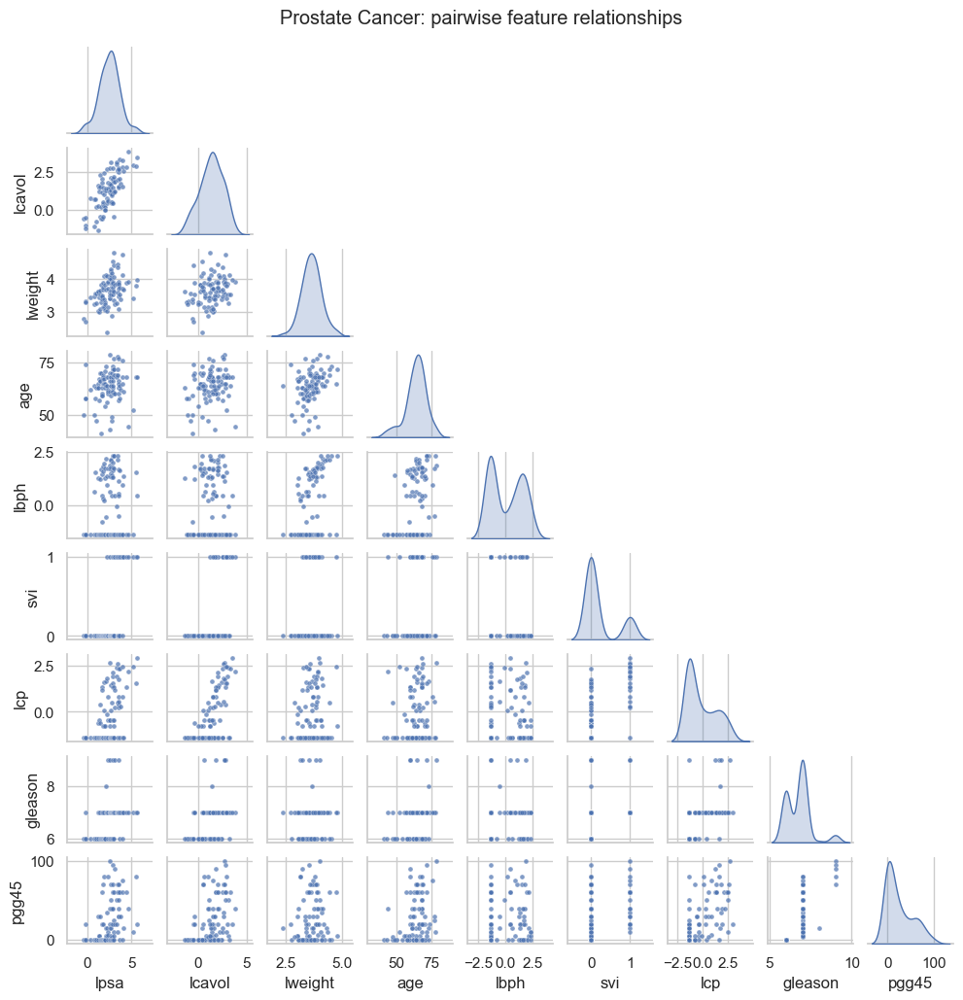

In [3]:
# Original notebook: use a scatterplot matrix to inspect feature relationships.
sns.pairplot(df, vars=[target, *features], height=1.12, corner=True, diag_kind="kde",
             plot_kws={"s": 13, "alpha": 0.70})
plt.suptitle("Prostate Cancer: pairwise feature relationships", y=1.02)
plt.show()


**Split and correlations.** The heatmap below measures how strongly each pair of variables moves together, using the 67 training patients only: $r=+1$ always move together, $r=-1$ always move oppositely, $r\approx0$ no linear relationship (red = positive, blue = negative). The last row is the correlation with the target `lpsa`.

Several features are strongly correlated with **each other**: `gleason`–`pgg45` 0.76, `lcavol`–`lcp` 0.69, `svi`–`lcp` 0.67. This is exactly the problem Section 4 fixes: such features carry overlapping information, and plain OLS can split the credit between them in unstable ways — Section 3 even gives `lcp` a *negative* coefficient although its own correlation with `lpsa` is positive.

Training: 67 samples | Test: 30 samples


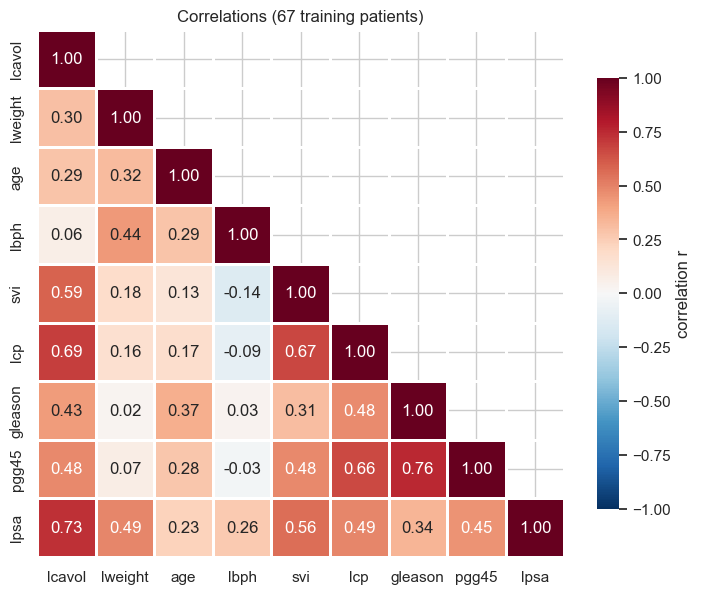

In [4]:
# Preserve the 'train' flags supplied with the original dataset.
train_mask = df["train"].eq("T").to_numpy()
X, y = df[features].to_numpy(dtype=float), df[target].to_numpy(dtype=float)
X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

print(f"Training: {X_train.shape[0]} samples | Test: {X_test.shape[0]} samples")
# Correlations on the training patients only: the 8 features and the target lpsa.
corr = df.loc[train_mask, [*features, target]].corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=1,
            cbar_kws={"label": "correlation r", "shrink": 0.8}, ax=ax)
ax.set_title("Correlations (67 training patients)")
plt.show()

## 3. Ordinary Least Squares (OLS) — NumPy closed form

**The model, in matrix form.** With $n=67$ training patients and $d=8$ features, stack every patient into one equation:

$$\mathbf y=\begin{bmatrix}y_1\\y_2\\\vdots\\y_n\end{bmatrix},\qquad
X=\begin{bmatrix}1&x_{11}&\cdots&x_{1d}\\1&x_{21}&\cdots&x_{2d}\\\vdots&\vdots&\ddots&\vdots\\1&x_{n1}&\cdots&x_{nd}\end{bmatrix},\qquad
\hat{\mathbf y}=X\boldsymbol\beta.$$

Row $i$ of $X$ is patient $i$: a leading 1 (for the intercept $\beta_0$) followed by `lcavol`$_i$, `lweight`$_i$, …, `pgg45`$_i$. OLS picks $\boldsymbol\beta$ to minimize the **residual sum of squares (RSS)**, also called the sum of squared errors (SSE):

$$\boxed{\hat{\boldsymbol\beta}_{\mathrm{OLS}}=\arg\min_{\boldsymbol\beta}\|X\boldsymbol\beta-\mathbf y\|_2^2.}$$

With $n=67>d+1=9$, OLS cannot make every residual exactly 0 — it only makes their squared sum as small as possible.

**Deriving the closed form.** Expand the objective:

$$L(\boldsymbol\beta)=(X\boldsymbol\beta-\mathbf y)^T(X\boldsymbol\beta-\mathbf y)=\boldsymbol\beta^TX^TX\boldsymbol\beta-2\boldsymbol\beta^TX^T\mathbf y+\mathbf y^T\mathbf y,$$

take the gradient with respect to $\boldsymbol\beta$, and set it to zero:

$$\nabla_{\boldsymbol\beta}L=2X^TX\boldsymbol\beta-2X^T\mathbf y=0\quad\Longrightarrow\quad X^TX\boldsymbol\beta=X^T\mathbf y.$$

This is the **normal equation**. If $X^TX$ is invertible, left-multiply both sides by its inverse:

$$\boxed{\hat{\boldsymbol\beta}=(X^TX)^{-1}X^T\mathbf y.}$$

Unlike a neural network, there is no gradient-descent loop here — $\hat{\boldsymbol\beta}$ comes out of one linear-algebra formula.

**When $X^TX$ isn't invertible.** This happens when features are highly correlated or $X$ is not full column rank — exactly the situation Section 1's correlation heatmap already flagged (`lcavol`–`lcp`, `svi`–`lcp`, `gleason`–`pgg45`). Then $(X^TX)^{-1}$ either doesn't exist or is numerically unstable even when it technically does. The fix is to never form the inverse: solve $X^TX\hat\beta=X^Ty$ directly (`np.linalg.solve`) instead of computing $(X^TX)^{-1}$ explicitly, and fall back to the SVD / pseudoinverse (`np.linalg.lstsq`) for the minimum-norm solution when $X^TX$ is singular or ill-conditioned. Below we compute $\hat{\boldsymbol\beta}$ **from scratch** with the normal equation, then cross-check it two ways — each check has a different job:

- **`np.linalg.lstsq`** confirms the SVD/pseudoinverse route above gives the same answer here (it must, since $X^TX$ happens to be invertible for this data) and is the one to trust if it weren't.
- **`statsmodels.OLS`** solves the same normal equation again with a standard library, which additionally reports the standard errors and $t$-values below — neither NumPy nor a bare-bones `LinearRegression` computes those.

In [5]:
# Fit the scaler on training data ONLY (no peeking at test samples).
scaler = StandardScaler().fit(X_train)
X_train_z = scaler.transform(X_train)
X_test_z = scaler.transform(X_test)

# Add an intercept column manually.
X_train_design = np.c_[np.ones(len(X_train_z)), X_train_z]
X_test_design = np.c_[np.ones(len(X_test_z)), X_test_z]

# OLS solution from the normal equation (8 predictors + 1 intercept).
beta_normal = np.linalg.solve(X_train_design.T @ X_train_design,
                              X_train_design.T @ y_train)
# A more numerically robust implementation of least squares.
beta_lstsq, *_ = np.linalg.lstsq(X_train_design, y_train, rcond=None)

print("Normal-equation coefficients:", np.round(beta_normal, 3))
print("Max difference from lstsq:", np.max(np.abs(beta_normal - beta_lstsq)))
assert np.allclose(beta_normal, beta_lstsq, atol=1e-8)

Normal-equation coefficients: [ 2.452  0.711  0.29  -0.141  0.21   0.307 -0.287 -0.021  0.275]
Max difference from lstsq: 1.4432899320127035e-15


In [6]:
# Compare with a standard statistics library.
statsmodels_ols = sm.OLS(y_train, X_train_design).fit()

print("NumPy vs statsmodels max difference:",
      np.max(np.abs(beta_normal - statsmodels_ols.params)))

# Equivalent to Table 3.2 style: coefficients, standard errors, and t-statistics.
ols_table = pd.DataFrame({
    "Term": ["Intercept", *features],
    "Coefficient": statsmodels_ols.params,
    "Std. Error": statsmodels_ols.bse,
    "t-value": statsmodels_ols.tvalues,
})
display(ols_table.round(3))

ols_pred = X_test_design @ beta_normal
ols_test_mse = mean_squared_error(y_test, ols_pred)
print(f"OLS test MSE: {ols_test_mse:.3f}")

NumPy vs statsmodels max difference: 1.3877787807814457e-15


,Term,Coefficient,Std. Error,t-value
0,Intercept,2.452,0.087,28.182
1,lcavol,0.711,0.133,5.366
2,lweight,0.290,0.106,2.751
3,age,-0.141,0.101,-1.396
4,lbph,0.210,0.102,2.056
5,svi,0.307,0.124,2.469
6,lcp,-0.287,0.154,-1.867
7,gleason,-0.021,0.142,-0.147
8,pgg45,0.275,0.158,1.738


OLS test MSE: 0.521


**Predicted vs actual.** Each dot is one patient; a perfect model would put every dot on the dashed diagonal. The vertical distance from a dot to the diagonal is that patient's residual $y_i-\hat y_i$, and the MSE is the average squared residual. The training MSE is lower than the test MSE because OLS chose $\hat\beta$ to fit exactly these 67 patients.

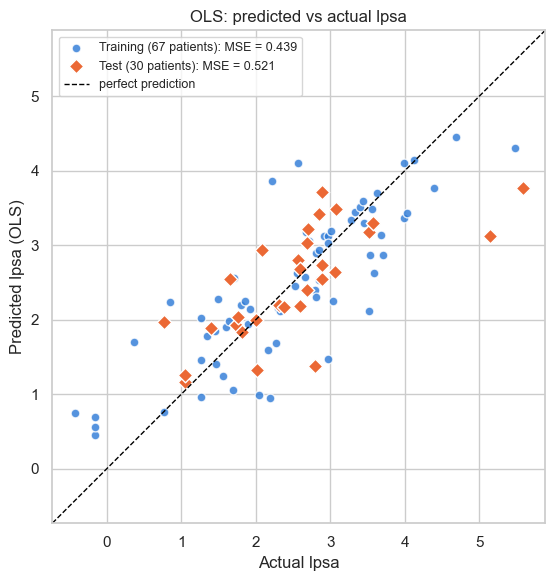

In [7]:
TRAIN_COLOR, TEST_COLOR = "#2a78d6", "#eb6834"
ols_train_pred = X_train_design @ beta_normal
ols_train_mse = mean_squared_error(y_train, ols_train_pred)

fig, ax = plt.subplots(figsize=(6.8, 6.4))
ax.scatter(y_train, ols_train_pred, s=40, color=TRAIN_COLOR, alpha=0.8, edgecolor="white",
           label=f"Training (67 patients): MSE = {ols_train_mse:.3f}")
ax.scatter(y_test, ols_pred, s=55, marker="D", color=TEST_COLOR, edgecolor="white",
           label=f"Test (30 patients): MSE = {ols_test_mse:.3f}")
lims = [min(y.min(), ols_train_pred.min(), ols_pred.min()) - 0.3,
        max(y.max(), ols_train_pred.max(), ols_pred.max()) + 0.3]
ax.plot(lims, lims, color="black", ls="--", lw=1, label="perfect prediction")
ax.set(xlim=lims, ylim=lims, aspect="equal", xlabel="Actual lpsa", ylabel="Predicted lpsa (OLS)",
       title="OLS: predicted vs actual lpsa")
ax.legend(loc="upper left", fontsize=9)
plt.show()


## 4. Ridge vs Lasso: adding a penalty

**Why regularization?** OLS in Section 3 picks $\beta$ to fit the 67 training patients exactly, with no limit on how large $\beta$ can get. When features are correlated — Section 1's heatmap already flagged `lcavol`–`lcp` (0.69), `svi`–`lcp` (0.67), `gleason`–`pgg45` (0.76) — many different combinations of $\beta$ fit this training sample almost equally well, so the particular $\beta$ OLS happens to pick becomes sensitive to noise: a slightly different sample of 67 patients could give noticeably different coefficients. Section 3 already showed a symptom of exactly this: `lcp`'s own correlation with `lpsa` is **+0.49**, yet its OLS coefficient is **−0.287** — a sign flip caused entirely by what the correlated features `lcavol` and `svi` are doing. **Regularization fixes this by penalizing large $|\beta_j|$**, trading a little bias for much less variance (Section 6 makes this trade-off precise).

**The two penalties:**

$$\text{Ridge }(L_2):\quad\hat\beta=\arg\min_{\beta_0,\beta}\Bigl\{\textstyle\sum_i(y_i-\beta_0-x_i^T\beta)^2+\alpha\sum_j\beta_j^2\Bigr\}$$

$$\text{Lasso }(L_1):\quad\hat\beta=\arg\min_{\beta_0,\beta}\Bigl\{\textstyle\frac{1}{2n}\sum_i(y_i-\beta_0-x_i^T\beta)^2+\alpha\sum_j|\beta_j|\Bigr\}$$

(matching scikit-learn's `Ridge`/`Lasso` conventions; $\beta_0$ is never penalized, and because the penalty looks at the *size* of $\beta_j$, standardizing the features first is required — a feature on a ×100 larger scale would otherwise be forced to an unfairly small coefficient just to keep the penalty small.)

Both shrink coefficients toward 0 as $\alpha$ grows, but differently:

| | Ridge ($L_2$) | Lasso ($L_1$) |
|---|---|---|
| Penalty on one coefficient | $\beta_j^2$ | $\lvert\beta_j\rvert$ |
| Slope of the penalty as $\beta_j\to 0$ | $\to 0$ (flattens out) | stays $\pm1$ (a kink at 0) |
| Effect on $\hat\beta_j$ | shrinks every coefficient, but **never exactly 0** | can push a coefficient **exactly to 0** — drops the feature |
| What it buys you | smaller, more stable coefficients | the above, **plus automatic feature selection** |

The flat gradient of $\beta_j^2$ at $\beta_j=0$ means Ridge always has a reason to nudge $\beta_j$ away from 0 by a little; the constant-slope kink in $|\beta_j|$ means Lasso can instead "win" outright and hold a coefficient at exactly 0. The animation right below shows the same fact geometrically.

We retain the **alpha grids** and **10-fold cross-validation** from the original example, picking the alpha with the lowest CV error. In modern scikit-learn, we put standardization in a `Pipeline` so it is fitted separately inside each CV training fold.

**A concrete example: why smaller coefficients matter.** The 67 training patients are just *one* sample we happened to collect; a trustworthy model should not change wildly if a few different patients had been sampled instead. To check this, resample the 67 patients **with replacement** 300 times (a *bootstrap*) and refit on each resample — once with plain OLS, once with Ridge at a moderate $\alpha=20$ (just for illustration; Section 5 shows how to choose $\alpha$ properly). Look at `lcavol` and `lcp`, the most correlated pair of features (correlation 0.69).

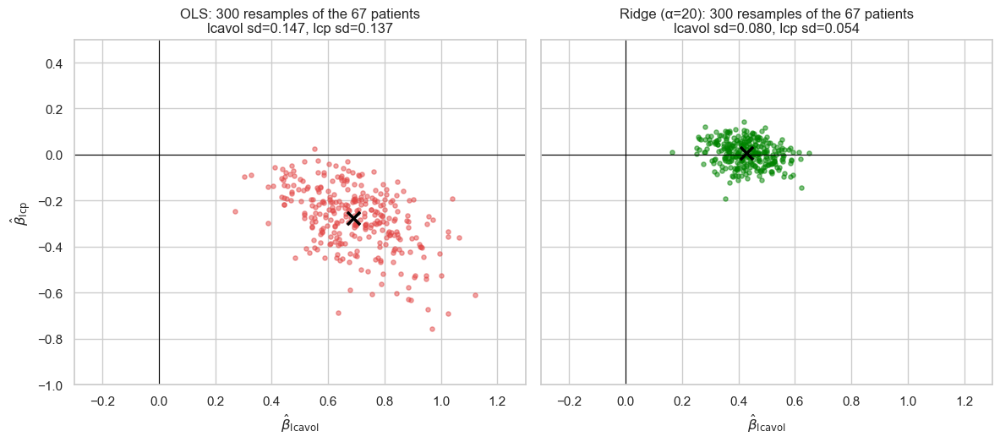

OLS:   lcp is negative in 99.7% of resamples (even though corr(lcp, lpsa) = +0.49)
Ridge: lcp is negative in 44.7% of resamples


In [8]:
rng_boot = np.random.default_rng(0)
n_boot = 300
illustration_alpha = 20.0                     # a moderate value, only to make the point here
j1, j2 = features.index("lcavol"), features.index("lcp")

boot_ols, boot_ridge = [], []
for _ in range(n_boot):
    idx = rng_boot.integers(0, len(X_train), len(X_train))        # sample patients with replacement
    Xb, yb = X_train[idx], y_train[idx]
    scaler_b = StandardScaler().fit(Xb)                           # re-fit the scaler on THIS resample
    Zb, yb_c = scaler_b.transform(Xb), yb - yb.mean()
    boot_ols.append(np.linalg.solve(Zb.T @ Zb, Zb.T @ yb_c))       # plain OLS, no penalty
    boot_ridge.append(Ridge(alpha=illustration_alpha).fit(Zb, yb).coef_)
boot_ols, boot_ridge = np.array(boot_ols), np.array(boot_ridge)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), sharex=True, sharey=True)
for ax, coefs, name, color in zip(axes, [boot_ols, boot_ridge], ["OLS", f"Ridge (α={illustration_alpha:g})"],
                                  ["#e34948", "#008300"]):
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(0, color="black", lw=0.8)
    ax.scatter(coefs[:, j1], coefs[:, j2], s=14, alpha=0.5, color=color)
    ax.scatter(coefs[:, j1].mean(), coefs[:, j2].mean(), s=120, marker="x", color="black", linewidth=2.5)
    ax.set(xlim=(-0.3, 1.3), ylim=(-1.0, 0.5), xlabel=r"$\hat\beta_{\mathrm{lcavol}}$",
           title=f"{name}: 300 resamples of the 67 patients\n"
                 f"lcavol sd={coefs[:, j1].std():.3f}, lcp sd={coefs[:, j2].std():.3f}")
axes[0].set_ylabel(r"$\hat\beta_{\mathrm{lcp}}$")
plt.tight_layout(); plt.show()

print(f"OLS:   lcp is negative in {np.mean(boot_ols[:, j2] < 0):.1%} of resamples "
      f"(even though corr(lcp, lpsa) = +0.49)")
print(f"Ridge: lcp is negative in {np.mean(boot_ridge[:, j2] < 0):.1%} of resamples")


**Reading the plot.** Each dot is one resample's fitted coefficients for `lcavol` and `lcp`; the black × is their average. OLS's cloud (left) is long and tilted — when a resample happens to give `lcavol` a larger coefficient, `lcp`'s drops to compensate, because the two features carry overlapping information and OLS can trade credit between them however the noise in that particular sample allows. `lcp` ends up **negative in 99.7% of resamples**, confidently contradicting its own positive correlation with `lpsa` (+0.49) almost every time — not a fluke of Section 3's particular split, but a systematic symptom of the correlation. Ridge's cloud (right) is a tight blob centered near the origin: both the spread (`lcp` standard deviation 0.054 vs OLS's 0.137) and the swing in sign (45% negative, no longer a near-certainty) shrink substantially. **This is the concrete payoff of smaller coefficients: the model's story about each feature stops depending so heavily on exactly which 67 patients happened to be sampled.**

**Animation: why Lasso gives exact zeros.** The penalized problems have an equivalent *constrained* form: for each $\alpha$ there is a budget $t$ such that Lasso minimizes the RSS subject to $\sum_j|\beta_j|\le t$, and Ridge subject to $\sum_j\beta_j^2\le t^2$. With two standardized features, `lcavol` and `lweight`, we can draw this in the $(\beta_1,\beta_2)$ plane:

- The gray ellipses are contours of the RSS; their center (×) is the OLS solution.
- The shaded region is the budget: a **diamond** for $L_1$ (Lasso), a **disk** for $L_2$ (Ridge).
- The solution (dot) is the point of the region with the smallest RSS: where the growing ellipse first touches the region (bold contour).

The diamond has **corners on the axes**, so the ellipse often touches a corner first; there $\beta_{\text{lweight}}=0$ exactly. The disk has no corners, so Ridge shrinks both coefficients but sets neither to 0. Once the budget contains the OLS point, both give OLS.

In [9]:
# Two standardized features (Section 3 scaling), so the coefficients live in a plane.
pair = [features.index("lcavol"), features.index("lweight")]
Z2 = X_train_z[:, pair]
y_c = y_train - y_train.mean()                         # the intercept is not penalized
beta_ols_2d = np.linalg.solve(Z2.T @ Z2, Z2.T @ y_c)


def rss_2d(b):
    return np.sum((y_c - Z2 @ b) ** 2)


# Lasso solution for an L1 budget t: interpolate the exact (piecewise-linear) path.
_, _, path_2d = lars_path(Z2, y_c, method="lasso")
path_l1 = np.abs(path_2d).sum(axis=0)


def lasso_2d(t):
    return np.array([np.interp(t, path_l1, coef) for coef in path_2d])


# Ridge solution for an L2 budget t: find alpha with ||beta(alpha)||_2 = t by bisection on log10(alpha).
def ridge_2d(t):
    if t >= np.linalg.norm(beta_ols_2d):
        return beta_ols_2d
    lo, hi = -6.0, 6.0
    for _ in range(60):
        mid = (lo + hi) / 2
        b = np.linalg.solve(Z2.T @ Z2 + 10**mid * np.eye(2), Z2.T @ y_c)
        lo, hi = (mid, hi) if np.linalg.norm(b) > t else (lo, mid)
    return b


g1, g2 = np.meshgrid(np.linspace(-0.45, 1.15, 220), np.linspace(-0.6, 1.0, 220))
rss_grid = np.sum((y_c[:, None, None] - Z2[:, [0]][..., None] * g1 - Z2[:, [1]][..., None] * g2) ** 2, axis=0)
rss_min = rss_2d(beta_ols_2d)
background_levels = rss_min + (rss_grid.max() - rss_min) * np.linspace(0.02, 0.9, 9) ** 2
budgets_2d = np.linspace(0.02, 1.2, 24)
lasso_trace = np.array([lasso_2d(t) for t in budgets_2d])
ridge_trace = np.array([ridge_2d(t) for t in budgets_2d])
REGION_COLOR, LASSO_2D, RIDGE_2D = "#86b6ef", "#e34948", "#008300"

fig, axes = plt.subplots(1, 2, figsize=(13, 6.4))
fig.subplots_adjust(left=0.07, right=0.97, wspace=0.2, top=0.86, bottom=0.1)


def draw_panel(ax, region, solution, trace, color, title):
    ax.cla()
    ax.contour(g1, g2, rss_grid, levels=background_levels, colors="#b5b4ae", linewidths=0.8)
    ax.add_patch(region)
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(0, color="black", lw=0.8)
    ax.plot(trace[:, 0], trace[:, 1], color=color, lw=1.5, alpha=0.6)
    if rss_2d(solution) > rss_min + 1e-6:              # bold contour that touches the region
        ax.contour(g1, g2, rss_grid, levels=[rss_2d(solution)], colors=color, linewidths=2.2)
    ax.scatter(*beta_ols_2d, marker="x", s=90, color="black", zorder=4)
    ax.annotate("OLS", beta_ols_2d, xytext=(8, 6), textcoords="offset points")
    ax.scatter(*solution, s=110, color=color, edgecolor="white", linewidth=2, zorder=5)
    ax.set(xlim=(-0.45, 1.15), ylim=(-0.6, 1.0), aspect="equal",
           xlabel=r"$\beta_1$ (lcavol)", ylabel=r"$\beta_2$ (lweight)", title=title)


def update(k):
    t = budgets_2d[k]
    b_lasso, b_ridge = lasso_trace[k], ridge_trace[k]
    diamond = plt.Polygon([[t, 0], [0, t], [-t, 0], [0, -t]], facecolor=REGION_COLOR, alpha=0.35,
                          edgecolor="#2a78d6", lw=1.5)
    disk = plt.Circle((0, 0), t, facecolor=REGION_COLOR, alpha=0.35, edgecolor="#2a78d6", lw=1.5)
    corner = "  (corner: lweight = 0 exactly)" if b_lasso[1] == 0 and b_lasso[0] != 0 else ""
    draw_panel(axes[0], diamond, b_lasso, lasso_trace[:k + 1], LASSO_2D,
               f"Lasso: |β1| + |β2| ≤ {t:.2f}\nβ = ({b_lasso[0]:.3f}, {b_lasso[1]:.3f}){corner}")
    draw_panel(axes[1], disk, b_ridge, ridge_trace[:k + 1], RIDGE_2D,
               f"Ridge: β1² + β2² ≤ {t:.2f}²\nβ = ({b_ridge[0]:.3f}, {b_ridge[1]:.3f})")
    fig.suptitle(f"Budget t = {t:.2f}   (OLS: β = ({beta_ols_2d[0]:.3f}, {beta_ols_2d[1]:.3f}))", fontsize=12)


show_animation(fig, update, frames=len(budgets_2d), interval=200)


## 5. Model selection by K-fold cross-validation

For each alpha, split the 67 training examples into 10 folds. Fit on 9 folds and evaluate on the held-out fold; repeat 10 times and average the MSE. **Do not use the final 30 test examples to choose alpha.** The alpha with the lowest average CV MSE is selected.

In [10]:
cv = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

def regularization_cv(model_class, alpha_grid):
    """Compute 10-fold CV MSE per alpha and select by the 1-SE rule."""
    alpha_grid = np.asarray(alpha_grid, dtype=float)
    fold_errors = []
    for alpha in alpha_grid:
        # Prevent leakage: scaler fits only on the 9 training folds each time.
        pipeline = make_pipeline(StandardScaler(), model_class(alpha=float(alpha), max_iter=30000)
                                 if model_class is Lasso else model_class(alpha=float(alpha)))
        errors = -cross_val_score(pipeline, X_train, y_train, cv=cv,
                                  scoring="neg_mean_squared_error")
        fold_errors.append(errors)

    fold_errors = np.asarray(fold_errors)
    means = fold_errors.mean(axis=1)
    se = fold_errors.std(axis=1, ddof=1) / np.sqrt(cv.get_n_splits())
    selected_idx = int(np.argmin(means))               # the alpha with the lowest mean CV MSE
    chosen_alpha = float(alpha_grid[selected_idx])
    final_model = make_pipeline(StandardScaler(), model_class(alpha=chosen_alpha, max_iter=30000)
                                if model_class is Lasso else model_class(alpha=chosen_alpha))
    final_model.fit(X_train, y_train)
    return {"alphas": alpha_grid, "cv_mse": means, "cv_se": se,
            "selected_idx": selected_idx, "model": final_model}

# Source notebook's alpha grids, from strongest to weakest penalty.
ridge_alphas = [436, 165, 82, 44, 27, 12, 4, 1e-5]
lasso_alphas = [0.680, 0.380, 0.209, 0.100, 0.044, 0.027, 0.012, 0.001]

ridge_result = regularization_cv(Ridge, ridge_alphas)
lasso_result = regularization_cv(Lasso, lasso_alphas)

for name, result in [("Ridge", ridge_result), ("Lasso", lasso_result)]:
    idx = result["selected_idx"]
    mse = mean_squared_error(y_test, result["model"].predict(X_test))
    print(f"{name:5s} selected alpha = {result['alphas'][idx]:.5g}; "
          f"CV MSE = {result['cv_mse'][idx]:.3f}; test MSE = {mse:.3f}")

Ridge selected alpha = 1e-05; CV MSE = 0.574; test MSE = 0.521
Lasso selected alpha = 0.001; CV MSE = 0.574; test MSE = 0.518


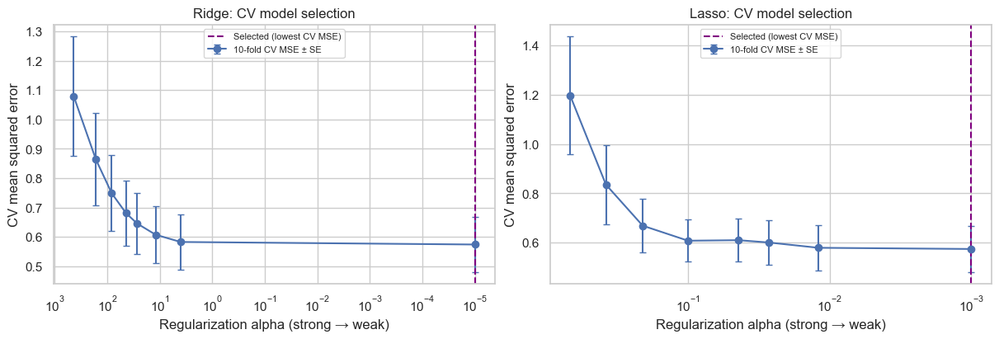

In [11]:
# Reproduce the original notebook's central idea: CV error curves + 1-SE threshold.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, (name, result) in zip(axes, [("Ridge", ridge_result), ("Lasso", lasso_result)]):
    a = result["alphas"]
    ax.errorbar(a, result["cv_mse"], yerr=result["cv_se"],
                marker="o", capsize=3, linewidth=1.5, label="10-fold CV MSE ± SE")
    ax.axvline(a[result["selected_idx"]], color="purple", ls="--", label="Selected (lowest CV MSE)")
    ax.set_xscale("log"); ax.invert_xaxis()  # larger alpha (simpler) on the left
    ax.set(title=f"{name}: CV model selection", xlabel="Regularization alpha (strong → weak)",
           ylabel="CV mean squared error")
    ax.legend(fontsize=8)
plt.show()

,OLS,Ridge,Lasso
lcavol,0.711,0.711,0.708
lweight,0.290,0.290,0.290
age,-0.141,-0.141,-0.140
lbph,0.210,0.210,0.209
svi,0.307,0.307,0.305
lcp,-0.287,-0.287,-0.280
gleason,-0.021,-0.021,-0.016
pgg45,0.275,0.275,0.269


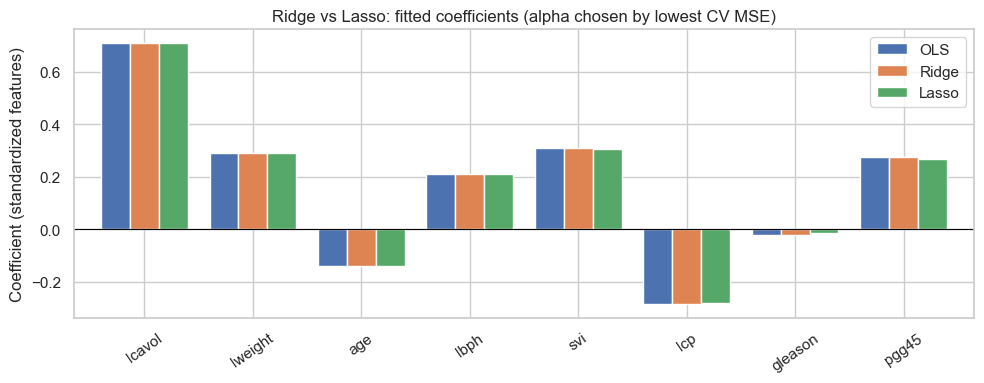

In [12]:
# Compare fitted coefficients: OLS, Ridge, Lasso (all on standardized predictors).
coef_table = pd.DataFrame({
    "OLS": statsmodels_ols.params[1:],
    "Ridge": ridge_result["model"].named_steps["ridge"].coef_,
    "Lasso": lasso_result["model"].named_steps["lasso"].coef_,
}, index=features)
display(coef_table.round(3))

ax = coef_table.plot(kind="bar", figsize=(10, 4), width=0.8, rot=35)
ax.axhline(0, color="black", lw=0.8)
ax.set(ylabel="Coefficient (standardized features)",
       title="Ridge vs Lasso: fitted coefficients (alpha chosen by lowest CV MSE)")
plt.tight_layout(); plt.show()

**Why neither model shrinks much here.** The alpha chosen by the lowest CV MSE is very weak for both models — Ridge selects $\alpha\approx10^{-5}$, Lasso $\alpha=0.001$ — so on this split, no amount of CV-driven regularization actually helps much: the curves above are nearly flat and bottom out close to no penalty at all. Neither model deviates much from OLS, and Lasso doesn't zero out any feature this time. The mechanism from Section 4 — Ridge shrinking continuously, Lasso hitting exact zeros — is still correct; it just doesn't show up at *this* alpha. Section 4's bootstrap and geometry demos used a stronger, illustrative $\alpha$ on purpose to make that mechanism visible.

### Coefficient paths: Lasso vs forward stagewise

Instead of eight alpha values, we now follow the **entire** Lasso solution path on the standardized training data. The x-axis is the size of the coefficient vector, $\|\beta(\lambda)\|_1=\sum_j|\beta_j|$. At $\|\beta\|_1=0$ the penalty is so strong that every coefficient is 0; as the penalty weakens, the features **enter one at a time**; at the right end there is no penalty left and the path reaches the OLS coefficients of Section 3.

**Forward stagewise regression** builds the model from many tiny steps: start from $\beta=0$; at every iteration, find the feature most correlated with the current residual $r=y-X\beta$ and move its coefficient by $\pm\varepsilon$ ($\varepsilon=0.01$), in the direction that reduces the residual. It stops when another step of size $\varepsilon$ would no longer reduce the residual sum of squares, about one step away from OLS. Its path is almost identical to the Lasso path. This gives an intuition for how the $L_1$ penalty selects features: the most useful feature (`lcavol`) is added first, and another feature only starts to move once it is as correlated with the residual as the features already in the model.

The dashed line marks the Lasso model chosen above by 10-fold CV.

Stagewise iterations: 221
Lasso path end vs OLS, max difference:     0.0
Stagewise path end vs OLS, max difference: 0.0153
Lasso entry order:     lcavol -> lweight -> svi -> lbph -> pgg45 -> age -> lcp -> gleason
Stagewise entry order: lcavol -> lweight -> svi -> lbph -> pgg45 -> age -> lcp -> gleason


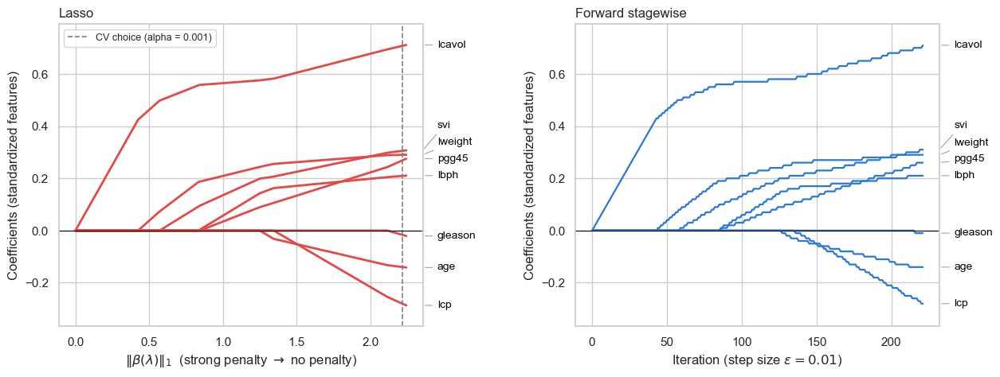

In [13]:
from matplotlib.transforms import blended_transform_factory

# Same standardization as before: mean and SD of the 67 training samples.
Z_train = StandardScaler().fit_transform(X_train)
y_centered = y_train - y_train.mean()        # the intercept is not penalized

# Lasso: the exact path from LARS (lasso variant); the coefficients are piecewise linear.
_, _, lasso_coefs = lars_path(Z_train, y_centered, method="lasso")   # shape (8, number of knots)
lasso_l1 = np.abs(lasso_coefs).sum(axis=0)                            # ||beta||_1 at each knot


def forward_stagewise(Z, y, eps=0.01, max_steps=1000):
    """Move one coefficient by +-eps per iteration: the one most correlated with the residual.
    Stop when no step of size eps reduces the residual sum of squares any more."""
    beta, residual = np.zeros(Z.shape[1]), y.copy()
    path = [beta.copy()]
    for _ in range(max_steps):
        corr = Z.T @ residual
        j = np.argmax(np.abs(corr))
        if np.abs(corr[j]) <= eps * (Z[:, j] @ Z[:, j]) / 2:   # the step would increase the RSS
            break
        step = eps * np.sign(corr[j])
        beta[j] += step
        residual -= step * Z[:, j]
        path.append(beta.copy())
    return np.array(path)                                                # shape (n_steps + 1, 8)


stagewise_path = forward_stagewise(Z_train, y_centered)
stagewise_l1 = np.abs(stagewise_path).sum(axis=1)

# Both paths end at (or, for stagewise, within about one step eps of) the OLS solution.
print("Stagewise iterations:", len(stagewise_path) - 1)
print("Lasso path end vs OLS, max difference:    ", np.abs(lasso_coefs[:, -1] - statsmodels_ols.params[1:]).max().round(4))
print("Stagewise path end vs OLS, max difference:", np.abs(stagewise_path[-1] - statsmodels_ols.params[1:]).max().round(4))

# Order in which the features become nonzero along each path.
lasso_entry = [features[j] for j in np.argsort([np.argmax(lasso_coefs[j] != 0) for j in range(len(features))], kind="stable")]
stagewise_entry = [features[j] for j in np.argsort([np.argmax(stagewise_path[:, j] != 0) for j in range(len(features))], kind="stable")]
print("Lasso entry order:    ", " -> ".join(lasso_entry))
print("Stagewise entry order:", " -> ".join(stagewise_entry))

# The Lasso model selected by CV above, placed on the same x-axis.
selected_lasso_alpha = lasso_result["alphas"][lasso_result["selected_idx"]]
selected_lasso_l1 = np.abs(lasso_result["model"].named_steps["lasso"].coef_).sum()

LASSO_COLOR, STAGEWISE_COLOR, GHOST_COLOR = "#e34948", "#2a78d6", "#dcdbd6"
coef_ylim = (lasso_coefs.min() - 0.08, lasso_coefs.max() + 0.08)


def label_line_ends(ax, end_values, active=None):
    """Feature names to the right of the axes, pushed apart so they do not overlap."""
    gap = 0.055 * (coef_ylim[1] - coef_ylim[0])
    order = np.argsort(end_values)
    y_text = np.asarray(end_values, dtype=float)[order]
    for i in range(1, len(y_text)):
        y_text[i] = max(y_text[i], y_text[i - 1] + gap)
    right_edge = blended_transform_factory(ax.transAxes, ax.transData)   # x in axes units, y in data units
    for y_label, j in zip(y_text, order):
        is_active = active is None or active[j]
        ax.annotate(features[j], xy=(1.0, end_values[j]), xycoords=right_edge,
                    xytext=(1.04, y_label), textcoords=right_edge, va="center", fontsize=10,
                    color="black" if is_active else "#a3a29d", annotation_clip=False,
                    arrowprops=dict(arrowstyle="-", color="#a3a29d", lw=0.8))


def style_path_axes(ax, title, xlabel):
    ax.axhline(0, color="black", lw=0.8)
    ax.set_ylim(*coef_ylim)
    ax.set_title(title, loc="left")
    ax.set(xlabel=xlabel, ylabel="Coefficients (standardized features)")


fig, (ax_lasso, ax_stage) = plt.subplots(1, 2, figsize=(13, 5))
fig.subplots_adjust(left=0.06, right=0.91, wspace=0.42, bottom=0.12)

ax_lasso.plot(lasso_l1, lasso_coefs.T, color=LASSO_COLOR, lw=2)
ax_lasso.axvline(selected_lasso_l1, color="gray", ls="--", lw=1.2,
                 label=f"CV choice (alpha = {selected_lasso_alpha:g})")
ax_lasso.legend(loc="upper left", fontsize=9)
style_path_axes(ax_lasso, "Lasso", r"$\|\beta(\lambda)\|_1$  (strong penalty $\rightarrow$ no penalty)")
label_line_ends(ax_lasso, lasso_coefs[:, -1])

ax_stage.plot(np.arange(len(stagewise_path)), stagewise_path, color=STAGEWISE_COLOR, lw=1.6)
style_path_axes(ax_stage, "Forward stagewise", r"Iteration (step size $\varepsilon = 0.01$)")
label_line_ends(ax_stage, stagewise_path[-1])
plt.show()


**A step-by-step trace.** At iteration 0, $\beta=0$ and the residual is just $y$ itself (centered). Every iteration does the same four things: (1) compute $Z^T r$ — how correlated each (standardized) feature is with the current residual; (2) pick the feature $j$ with the largest $|Z_j^Tr|$; (3) move only $\beta_j$ by $\pm\varepsilon=\pm0.01$, in the direction of $\mathrm{sign}(Z_j^Tr)$; (4) update the residual, $r\mathrel{-}=\,\varepsilon\cdot\mathrm{sign}(Z_j^Tr)\cdot Z_j$. Nothing else about $\beta$ changes on that iteration. Below are the first 5 iterations with the real numbers, followed by the point where the winner first changes.

In [14]:
# Trace forward_stagewise by hand, iteration by iteration, using the SAME Z_train/y_centered.
Z_demo, r_demo = Z_train.copy(), y_centered.copy()
rows = []
for it in range(1, 6):
    corr = Z_demo.T @ r_demo                      # how correlated each feature is with the residual
    j = np.argmax(np.abs(corr))                   # feature with the largest |correlation| wins
    step = 0.01 * np.sign(corr[j])                # move only that feature's coefficient by +-eps
    r_demo = r_demo - step * Z_demo[:, j]          # update the residual
    rows.append({"iteration": it, "winner": features[j], "corr[winner]": corr[j],
                 "step": step, "RSS after": r_demo @ r_demo})
display(pd.DataFrame(rows).round(3))

# Sanity check: this hand trace must match the first 5 steps of stagewise_path exactly.
beta_demo = np.zeros(len(features))
for row in rows:
    beta_demo[features.index(row["winner"])] += row["step"]
assert np.allclose(beta_demo, stagewise_path[5])

# Which coefficient actually moved at every iteration (exactly one per step, by construction).
winners = np.argmax(stagewise_path[1:] != stagewise_path[:-1], axis=1)
first_switch = int(np.argmax(winners != winners[0]))
print(f"'{features[winners[0]]}' wins every iteration from 1 to {first_switch} "
      f"({first_switch} times in a row); '{features[winners[first_switch]]}' is picked for the "
      f"first time at iteration {first_switch + 1}, once {features[winners[0]]}'s own correlation "
      f"with the residual has dropped below it.")


,iteration,winner,corr[winner],step,RSS after
0,1,lcavol,58.885,0.01,95.110
1,2,lcavol,58.215,0.01,93.953
2,3,lcavol,57.545,0.01,92.809
3,4,lcavol,56.875,0.01,91.678
4,5,lcavol,56.205,0.01,90.560


'lcavol' wins every iteration from 1 to 43 (43 times in a row); 'lweight' is picked for the first time at iteration 44, once lcavol's own correlation with the residual has dropped below it.


**Animation.** Both paths are traced as the budget $\|\beta\|_1$ grows from 0 (all coefficients 0) to the OLS value. For every frame, the Lasso panel shows the solution with that $\|\beta\|_1$, and the stagewise panel shows the first iteration that reaches the same $\|\beta\|_1$. Gray lines are the full paths; a feature's name turns black when its coefficient becomes nonzero. Use the slider to stop at any frame.

In [15]:
budgets = np.linspace(0, lasso_l1[-1], 46)    # ||beta||_1 shown in each frame
iterations = np.arange(len(stagewise_path))

fig, (ax_lasso, ax_stage) = plt.subplots(1, 2, figsize=(13, 5.4))
fig.subplots_adjust(left=0.06, right=0.91, wspace=0.42, top=0.84, bottom=0.12)


def update(k):
    t = budgets[k]
    # Lasso coefficients with ||beta||_1 = t (linear between the knots of the path).
    beta_lasso = np.array([np.interp(t, lasso_l1, coef) for coef in lasso_coefs])
    # First stagewise iteration whose ||beta||_1 reaches t (the last iteration in the final frame).
    reached = np.flatnonzero(stagewise_l1 >= t - 1e-9)
    k_stage = reached[0] if reached.size and k < len(budgets) - 1 else iterations[-1]
    beta_stage = stagewise_path[k_stage]

    for ax in (ax_lasso, ax_stage):
        ax.cla()

    # Left: Lasso
    ax_lasso.plot(lasso_l1, lasso_coefs.T, color=GHOST_COLOR, lw=1.5)
    traced = np.r_[lasso_l1[lasso_l1 < t], t]
    traced_coefs = np.array([np.interp(traced, lasso_l1, coef) for coef in lasso_coefs])
    ax_lasso.plot(traced, traced_coefs.T, color=LASSO_COLOR, lw=2)
    ax_lasso.axvline(t, color="black", ls="--", lw=1)
    ax_lasso.scatter(np.full(len(features), t), beta_lasso, s=40, color=LASSO_COLOR,
                     edgecolor="white", linewidth=1.5, zorder=3)
    style_path_axes(ax_lasso, rf"Lasso:  $\|\beta\|_1$ = {t:.2f}",
                    r"$\|\beta(\lambda)\|_1$  (strong penalty $\rightarrow$ no penalty)")
    label_line_ends(ax_lasso, lasso_coefs[:, -1], active=beta_lasso != 0)

    # Right: forward stagewise
    ax_stage.plot(iterations, stagewise_path, color=GHOST_COLOR, lw=1.5)
    ax_stage.plot(iterations[:k_stage + 1], stagewise_path[:k_stage + 1], color=STAGEWISE_COLOR, lw=1.6)
    ax_stage.axvline(k_stage, color="black", ls="--", lw=1)
    ax_stage.scatter(np.full(len(features), k_stage), beta_stage, s=40, color=STAGEWISE_COLOR,
                     edgecolor="white", linewidth=1.5, zorder=3)
    style_path_axes(ax_stage, f"Forward stagewise:  iteration {k_stage}",
                    r"Iteration (step size $\varepsilon = 0.01$)")
    label_line_ends(ax_stage, stagewise_path[-1], active=beta_stage != 0)

    in_model = [name for name in lasso_entry if beta_lasso[features.index(name)] != 0]
    fig.suptitle(f"{len(in_model)} of {len(features)} features in the Lasso model"
                 + (": " + ", ".join(in_model) if in_model else ""), fontsize=12)


show_animation(fig, update, frames=len(budgets), interval=200)


## 6. Bias–variance tradeoff (short visual demo)

**This is a synthetic example, separate from the prostate data.** A low-complexity model tends to have more **bias**; a highly flexible model can change substantially across training samples (**variance**). Neither extreme necessarily achieves the lowest *test* error. We fit polynomials of different degrees to repeated noisy draws from the same underlying function.

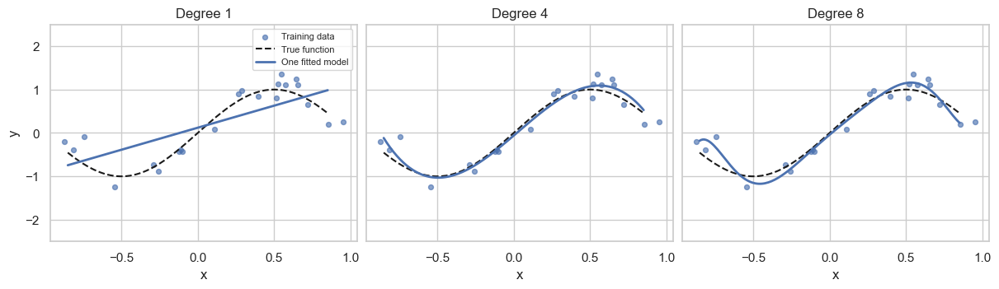

,Estimated bias²,Estimated variance,bias² + variance + noise
Degree,,,
1,0.146,0.025,0.261
4,0.002,0.032,0.123
8,0.008,0.569,0.667


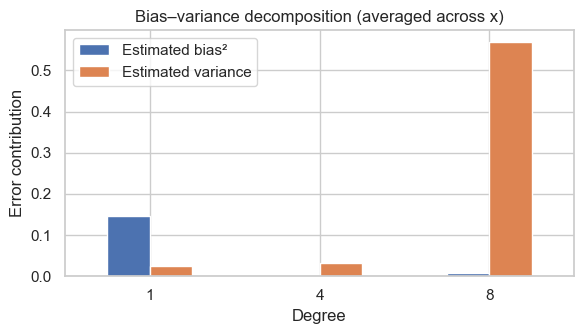

In [16]:
rng = np.random.default_rng(42)
xx = np.linspace(-0.85, 0.85, 160)
true_signal = np.sin(np.pi * xx)
noise_std = 0.30
n_train_synthetic = 22
n_trials = 100
poly_degrees = [1, 4, 8]
predictions = {degree: [] for degree in poly_degrees}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True, constrained_layout=True)
for trial in range(n_trials):
    x_sample = rng.uniform(-1, 1, n_train_synthetic)
    y_sample = np.sin(np.pi * x_sample) + rng.normal(0, noise_std, n_train_synthetic)
    for degree, ax in zip(poly_degrees, axes):
        model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
        model.fit(x_sample[:, None], y_sample)
        predictions[degree].append(model.predict(xx[:, None]))
        if trial == 0:
            ax.scatter(x_sample, y_sample, s=18, alpha=0.65, label="Training data")
            ax.plot(xx, true_signal, "k--", lw=1.5, label="True function")
            ax.plot(xx, predictions[degree][-1], lw=2, label="One fitted model")
            ax.set(title=f"Degree {degree}", xlabel="x", ylim=(-2.5, 2.5))
axes[0].set_ylabel("y")
axes[0].legend(fontsize=8)
plt.show()

# Bias and variance are averages over repeated training datasets.
rows = []
for degree in poly_degrees:
    preds = np.stack(predictions[degree])
    bias_squared = np.mean((preds.mean(axis=0) - true_signal)**2)
    variance = np.mean(np.var(preds, axis=0, ddof=0))
    rows.append({"Degree": degree, "Estimated bias²": bias_squared,
                 "Estimated variance": variance, "bias² + variance + noise":
                 bias_squared + variance + noise_std**2})
bv_table = pd.DataFrame(rows).set_index("Degree")
display(bv_table.round(3))
bv_table[["Estimated bias²", "Estimated variance"]].plot(kind="bar", figsize=(6, 3.5), rot=0)
plt.ylabel("Error contribution")
plt.title("Bias–variance decomposition (averaged across x)")
plt.tight_layout(); plt.show()

## 7. Compare final test errors

The **test set is only for final evaluation**, not for hyperparameter selection. OLS, Ridge, and Lasso are all evaluated on the original 30 held-out prostate samples.

,Model,Test MSE
2,Lasso (CV-selected),0.518
1,Ridge (CV-selected),0.521
0,OLS,0.521


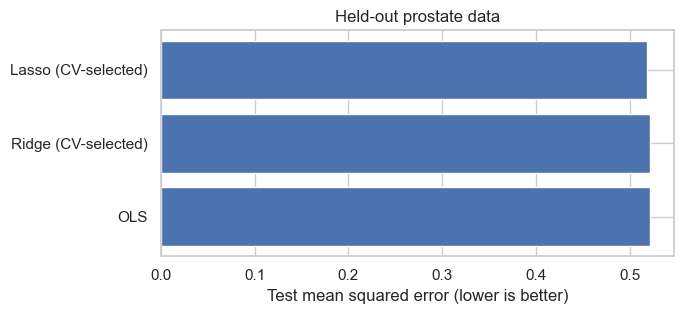

In [17]:
summary = pd.DataFrame([
    ("OLS", ols_test_mse),
    ("Ridge (CV-selected)", mean_squared_error(y_test, ridge_result["model"].predict(X_test))),
    ("Lasso (CV-selected)", mean_squared_error(y_test, lasso_result["model"].predict(X_test))),
], columns=["Model", "Test MSE"]).sort_values("Test MSE")
display(summary.round(3))

fig, ax = plt.subplots(figsize=(7, 3.3))
ax.barh(summary["Model"], summary["Test MSE"])
ax.invert_yaxis()
ax.set(xlabel="Test mean squared error (lower is better)", title="Held-out prostate data")
plt.tight_layout(); plt.show()